# APM_50441_EP - Machine Learning 2 - Lab 5: Recommender systems and text

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/APM-50441-EP/APM_50441_EP-2026-2027/blob/main/PC5/APM_50441_EP_Lab_5_simplified_with_solution.ipynb) or run it on your own computer (see *Working environment* below).

This lab illustrates the fifth lecture (*Recommender Systems, Text and Words*). Its goals are:
- to build the baselines of a recommender system (global mean, user and item biases) and to see the long tail,
- to implement an item-based collaborative filtering,
- to complete the rating matrix with a low-rank model: SVD, Soft-Impute, alternating least squares and a matrix factorization trained by stochastic gradient descent in PyTorch,
- to evaluate the recommendations with ranking metrics, and to see that a good RMSE does not make a good top-$10$ list.

The optional *To go further* part, after the core, can be skipped at first: it covers implicit feedback, evaluation issues (time, sampled metrics, exposure bias, feedback loops), cold start and hybrid models, sequential recommendation, and the text half of the lecture (bag of words, BM25, topic models, word vectors, tokenization, RNN and attention).

We use `Python` with `numpy`, `polars`, `seaborn`, `scikit-learn` and `PyTorch`. All the models are written by hand in `numpy` or `PyTorch`: the specialized libraries (`surprise`, `implicit`, `LightFM`) are not maintained for recent versions of `numpy`.

**Working environment.** Colab is the simplest option: open the notebook of this lab from the course repository (*Open in Colab* link) and run it. To work on your own computer, download the lab folder (the notebook and its files) or clone the course repository, and open the notebook in an IDE that runs Jupyter notebooks (VS Code with the Python and Jupyter extensions, JupyterLab, Spyder, PyCharm). Create a Python environment once with [`uv`](https://docs.astral.sh/uv/): `uv venv`, activate it (`source .venv/bin/activate`, or `.venv\Scripts\activate` on Windows) and `uv pip install jupyter`, or build the whole course environment with `uv sync` in `PC/env`; then select this environment as the kernel of the notebook. The installation cell below installs the packages of the lab into the Python running the notebook (Colab or your environment), and the data are read from the local files when they are present (otherwise they are downloaded).

**Use of AI.** AI assistants are allowed, but you must be able to explain every line you use, and you should answer the *predict before you run* questions before running the code: the suggested code may not be correct!

All the libraries of the core part are installed at once.

In [2]:
# Installs into the Python running this notebook: Colab, or locally an activated virtual environment
import sys
!uv pip install --python "{sys.executable}" "scikit-learn==1.9.1" "polars==1.44.2" "seaborn==0.13.2" "torch"

Using Python 3.12.14 environment at: ~\.venvs\apm50441
Checked 4 packages in 92ms


We use the MovieLens 100k data: $100\,000$ ratings ($1$ to $5$ stars) of $1682$ movies by $943$ users, collected by GroupLens in 1997-1998. Its license does not allow redistribution: it is downloaded from the GroupLens website.

In [3]:
import os
import urllib.request
if not os.path.exists("ml-100k.zip"):
  urllib.request.urlretrieve("https://files.grouplens.org/datasets/movielens/ml-100k.zip", "ml-100k.zip")

The data and a random split of the ratings ($80\%$ training, $10\%$ validation, $10\%$ test) are given. The identifiers of the users and the movies start at $1$ in the files: they are shifted to start at $0$, to be used as indices.

In [4]:
import io
import time
import zipfile
import numpy as np
import polars as pl
import seaborn.objects as so
import matplotlib.pyplot as plt
import torch
torch.set_num_threads(2)  # small models: a few threads are faster than many

GENRES = ["unknown", "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime", "Documentary", "Drama", "Fantasy",
          "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]
with zipfile.ZipFile("ml-100k.zip") as z:
  ratings = pl.read_csv(io.BytesIO(z.read("ml-100k/u.data")), separator="\t", has_header=False,
                        new_columns=["user", "item", "rating", "timestamp"])
  movies = pl.read_csv(io.BytesIO(z.read("ml-100k/u.item")), separator="|", has_header=False, encoding="latin1",
                       new_columns=["item", "title", "release", "video release", "url"] + GENRES)
  users = pl.read_csv(io.BytesIO(z.read("ml-100k/u.user")), separator="|", has_header=False,
                      new_columns=["user", "age", "gender", "occupation", "zip"])
ratings = ratings.with_columns(pl.col("user") - 1, pl.col("item") - 1)
movies = movies.with_columns(pl.col("item") - 1)
users = users.with_columns(pl.col("user") - 1)
n_users, n_items = users.height, movies.height
titles = np.array(movies["title"].to_list())

rng = np.random.default_rng(0)
part = rng.choice(3, size=ratings.height, p=[0.8, 0.1, 0.1])
train, valid, test = [ratings.filter(pl.Series(part == k)) for k in range(3)]
def arrays(df):
  return df["user"].to_numpy(), df["item"].to_numpy(), df["rating"].to_numpy().astype(float)
u_train, i_train, r_train = arrays(train)
u_valid, i_valid, r_valid = arrays(valid)
u_test, i_test, r_test = arrays(test)
def rmse(prediction, r):
  return np.sqrt(np.mean((prediction - r) ** 2))
{'users': n_users, 'movies': n_items, 'training ratings': train.height, 'validation ratings': valid.height, 'test ratings': test.height}

{'users': 943,
 'movies': 1682,
 'training ratings': 80184,
 'validation ratings': 9911,
 'test ratings': 9905}

## 1. The data and the baselines

**Question** What is the proportion of observed entries in the $943 \times 1682$ rating matrix? Plot the distribution of the ratings, and the number of ratings of each movie sorted in decreasing order (log scale). Which share of the ratings concerns the $10\%$ most rated movies? How many movies have fewer than $5$ ratings?

**Answer**

{'density': 0.06304669364224531, 'share of the 10% most rated movies': np.float64(0.42702), 'movies with fewer than 5 ratings': 333}


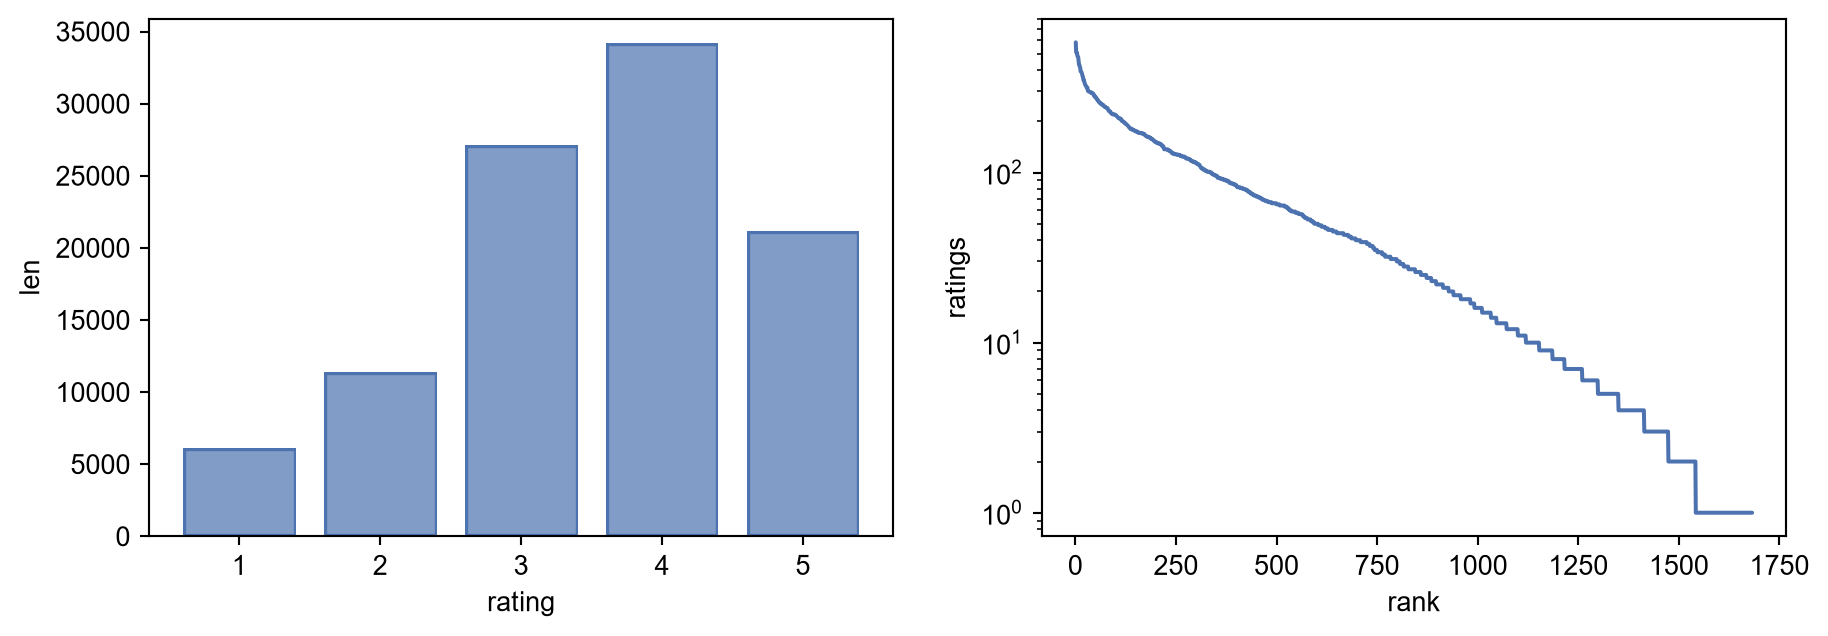

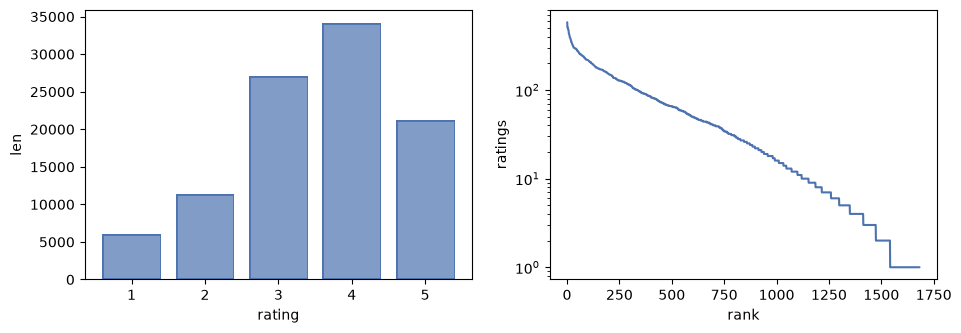

In [5]:
item_counts = np.bincount(ratings["item"].to_numpy(), minlength=n_items)
sorted_counts = np.sort(item_counts)[::-1]
print({'density': ratings.height / (n_users * n_items),
       'share of the 10% most rated movies': sorted_counts[:n_items // 10].sum() / ratings.height,
       'movies with fewer than 5 ratings': int((item_counts < 5).sum())})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
so.Plot(ratings.group_by("rating").len(), x="rating", y="len").add(so.Bar()).on(axes[0]).plot()
so.Plot(pl.DataFrame({"rank": np.arange(1, n_items + 1), "ratings": sorted_counts}), x="rank", y="ratings").add(so.Line()).scale(y="log").on(axes[1]).plot()

**Conclusion** Only $6.3\%$ of the entries of the matrix are observed (and every user rated at least $20$ movies, by construction of the dataset): the matrix is very sparse. The ratings are mostly positive (mode $4$, few $1$ and $2$): people watch, and rate, the movies they expect to like. The number of ratings per movie decreases exponentially with its rank (a straight line in log scale): the $10\%$ most rated movies receive $43\%$ of the ratings, while $333$ movies have fewer than $5$ ratings. This *long tail* is the main difficulty of recommendation: little is known about most items, and naive methods favor the head of the catalog.

---

The simplest predictor is the global mean $\mu$ of the training ratings. The *bias* model (lecture: *Ratings Issues*) adds a user effect and an item effect, $\hat r_{ui} = \mu + b_u + b_i$, fitted by penalized least squares:
$$\min_{b} \sum_{(u,i) \in \Omega} (r_{ui} - \mu - b_u - b_i)^2 + \lambda\Big(\sum_u b_u^2 + \sum_i b_i^2\Big).$$
For fixed item biases, the optimal user bias is $b_u = \frac{\sum_{i \in \Omega_u}(r_{ui} - \mu - b_i)}{|\Omega_u| + \lambda}$, and symmetrically: the problem is solved by alternating these updates (`np.bincount` with weights computes the sums over users or items).

**Question** Compute the validation RMSE of the global mean. Implement the bias model, choose $\lambda \in \{1, 2, 5, 10, 25\}$ on the validation set, and compare the $5$ movies with the highest mean rating with the $5$ movies with the highest bias $b_i$ (with their numbers of ratings). Why is the penalty needed? (Store the global mean in `mu` and the biases obtained with $\lambda = 5$ in `b_user` and `b_item`: they are used below.)

**Answer**

In [6]:
mu = r_train.mean()
def fit_biases(lam, iterations=10):
  b_user, b_item = np.zeros(n_users), np.zeros(n_items)
  n_user, n_item = np.bincount(u_train, minlength=n_users), np.bincount(i_train, minlength=n_items)
  for _ in range(iterations):
    b_user = np.bincount(u_train, r_train - mu - b_item[i_train], n_users) / (n_user + lam)
    b_item = np.bincount(i_train, r_train - mu - b_user[u_train], n_items) / (n_item + lam)
  return b_user, b_item
print({'global mean': rmse(mu, r_valid)} |
      {f'biases, lambda = {lam}': rmse(mu + b[0][u_valid] + b[1][i_valid], r_valid) for lam in [1, 2, 5, 10, 25] for b in [fit_biases(lam)]})
b_user, b_item = fit_biases(5)
movie_stats = (train.group_by("item").agg(pl.col("rating").mean().alias("mean rating"), pl.len().alias("ratings"))
               .join(pl.DataFrame({"item": np.arange(n_items), "title": titles, "bias": b_item}), on="item"))
pl.concat([movie_stats.sort("mean rating", descending=True).head(5), movie_stats.sort("bias", descending=True).head(5)])

{'global mean': np.float64(1.1280424763766483), 'biases, lambda = 1': np.float64(0.9434994916871586), 'biases, lambda = 2': np.float64(0.9427325291022475), 'biases, lambda = 5': np.float64(0.9426145020495051), 'biases, lambda = 10': np.float64(0.9448442548520164), 'biases, lambda = 25': np.float64(0.9547405528057157)}


item,mean rating,ratings,title,bias
i64,f64,u32,str,f64
813,5.0,1,"""Great Day in Harlem, A (1994)""",0.320067
1121,5.0,1,"""They Made Me a Criminal (1939)""",0.20713
1188,5.0,3,"""Prefontaine (1997)""",0.403841
1200,5.0,1,"""Marlene Dietrich: Shadow and L…",0.186304
1292,5.0,2,"""Star Kid (1997)""",0.238452
317,4.481172,239,"""Schindler's List (1993)""",1.038243
482,4.472362,199,"""Casablanca (1942)""",1.02843
168,4.438776,98,"""Wrong Trousers, The (1993)""",1.007254
407,4.43956,91,"""Close Shave, A (1995)""",0.990895


**Conclusion** The global mean has a validation RMSE of $1.13$; adding the user and item biases reduces it to $0.943$ (best $\lambda = 5$): a large part of the predictable variation is explained by users rating systematically high or low and by movies being better or worse than average. Without penalty, the movies with the highest mean rating are obscure movies rated $5$ by one or two users: their mean is pure noise. The penalty shrinks the bias of the movies with few ratings towards $0$ (as a prior, or as Bayesian average ratings), and the highest biases go to movies with hundreds of good ratings: *Schindler's List*, *Casablanca*, *The Shawshank Redemption*...

---

## 2. Item-based collaborative filtering

Collaborative filtering predicts a rating from the ratings of similar items (or users). We work on the *residuals* of the bias model, $\tilde r_{ui} = r_{ui} - \mu - b_u - b_i$, stored in a dense matrix `R` with zeros for the missing entries and a boolean mask `W` of the observed ones. The similarity of two items is the cosine of their residual columns. As two movies seen by few common users can get a large similarity by chance, it is *shrunk* towards $0$: $s_{ij} \times \frac{n_{ij}}{n_{ij} + \beta}$, $n_{ij}$ being the number of users who rated both.

In [7]:
R = np.zeros((n_users, n_items))
W = np.zeros((n_users, n_items), dtype=bool)
R[u_train, i_train] = r_train - mu - b_user[u_train] - b_item[i_train]
W[u_train, i_train] = True
baseline_valid = mu + b_user[u_valid] + b_item[i_valid]
baseline_test = mu + b_user[u_test] + b_item[i_test]

**Question** Compute the cosine similarities between the items, with and without the shrinkage ($\beta = 50$). Display the $5$ movies most similar to *Star Wars (1977)* in both cases. What does the shrinkage change?

**Answer**

In [8]:
norms = np.sqrt((R ** 2).sum(axis=0)) + 1e-9
similarity = (R.T @ R) / np.outer(norms, norms)
np.fill_diagonal(similarity, 0)
common = W.T.astype(float) @ W.astype(float)
shrunk_similarity = similarity * common / (common + 50)
star_wars = int(np.flatnonzero(titles == "Star Wars (1977)")[0])
pl.DataFrame({f'without shrinkage': titles[np.argsort(-similarity[star_wars])[:5]],
              'common users': common[star_wars, np.argsort(-similarity[star_wars])[:5]],
              'with shrinkage': titles[np.argsort(-shrunk_similarity[star_wars])[:5]]})

without shrinkage,common users,with shrinkage
str,f64,str
"""Return of the Jedi (1983)""",310.0,"""Return of the Jedi (1983)"""
"""Empire Strikes Back, The (1980…",214.0,"""Empire Strikes Back, The (1980…"
"""Raiders of the Lost Ark (1981)""",243.0,"""Raiders of the Lost Ark (1981)"""
"""Sting, The (1973)""",136.0,"""Sting, The (1973)"""
"""Indiana Jones and the Last Cru…",182.0,"""Indiana Jones and the Last Cru…"


**Conclusion** The most similar movies to *Star Wars* are its sequels *Return of the Jedi* and *The Empire Strikes Back*, then *Raiders of the Lost Ark*, *The Sting* and *Indiana Jones*: collaborative filtering finds the "same kind of movie" without any information on the content, only from the ratings. For such a popular movie, the shrinkage does not change the list, as all the neighbors share more than $100$ users with it; it matters for the movies with few ratings, whose cosines computed on a handful of common users can be close to $\pm 1$ by chance.

---

**Question** Predict the residual $\tilde r_{ui}$ by the weighted mean $\sum_{j \in N_k(i, u)} s_{ij}\tilde r_{uj} / \sum_{j}|s_{ij}|$ over the $k$ items rated by $u$ that are the most similar to $i$, and add it to the bias model. Compute the validation RMSE for $k \in \{10, 30, 100\}$ with the shrunk similarity.

**Answer**

In [9]:
def item_knn(sim, k, users, items):
  prediction = np.empty(len(users))
  for n, (u, i) in enumerate(zip(users, items)):
    rated = np.flatnonzero(W[u])
    s = sim[i, rated]
    top = np.argsort(-s)[:k]
    prediction[n] = s[top] @ R[u, rated[top]] / (np.abs(s[top]).sum() + 1e-9)
  return prediction
{f'item kNN, k = {k}': rmse(baseline_valid + item_knn(shrunk_similarity, k, u_valid, i_valid), r_valid) for k in [10, 30, 100]}

{'item kNN, k = 10': np.float64(0.9161443030633546),
 'item kNN, k = 30': np.float64(0.9059302832510945),
 'item kNN, k = 100': np.float64(0.9091179632449681)}

**Conclusion** The item-based collaborative filtering improves on the bias model: the validation RMSE goes from $0.943$ to $0.916$ with $k = 10$ neighbors and $0.906$ with $k = 30$, then slightly increases with $k = 100$ ($0.909$), as less similar movies dilute the prediction. As for any $k$-NN, $k$ trades variance (few neighbors) for bias (far neighbors).

---

## 3. Matrix completion

A low-rank model assumes that the matrix of the residuals is close to $UV^\top$, with $U \in \mathbb{R}^{n \times q}$ (the user factors) and $V \in \mathbb{R}^{p \times q}$ (the item factors). The truncated SVD of the zero-filled matrix is the best rank $q$ approximation of `R`, but it treats the missing entries as observed zeros. The weighted problem only fits the observed entries (lecture: *Weighted SVD*); the iterative algorithms below solve it, or its convex relaxation with the nuclear norm (PC5, Exercise 2).

**Question** Compute the SVD of the zero-filled residual matrix (`np.linalg.svd`), and the validation RMSE of the bias model plus its rank $q$ approximation, for $q \in \{1, 2, 5, 10, 20, 50\}$.

**Answer**

In [10]:
U, d, Vt = np.linalg.svd(R, full_matrices=False)
svd_rmse = {q: rmse(baseline_valid + ((U[:, :q] * d[:q]) @ Vt[:q])[u_valid, i_valid], r_valid) for q in [1, 2, 5, 10, 20, 50]}
svd_rmse

{1: np.float64(0.9338048780203969),
 2: np.float64(0.9315492621912524),
 5: np.float64(0.927471699622451),
 10: np.float64(0.9251964017638941),
 20: np.float64(0.9277423483300515),
 50: np.float64(0.9335565480739713)}

**Conclusion** The low-rank approximation of the zero-filled residual matrix only slightly improves on the bias model: $0.925$ at best ($q = 10$), worse than the item kNN. The SVD fits the $94\%$ of missing entries as if they were observed zeros: the factors mostly describe *which* movies were rated, and the predictions are shrunk towards $0$. The weighted problem, which fits only the observed entries, is needed.

---

*Hard-Impute* fills the missing entries with the current estimate $Z$ and projects on the matrices of rank $q$: $Z \leftarrow \text{SVD}_q\big(W \odot R + (1 - W) \odot Z\big)$. *Soft-Impute* replaces the projection by a soft thresholding of the singular values, $d_k \mapsto (d_k - \lambda)_+$, which is the proximal operator of $\lambda\|\cdot\|_*$: it solves $\min_Z \frac{1}{2}\|W \odot (R - Z)\|^2 + \lambda\|Z\|_*$ (PC5). A truncated randomized SVD (`randomized_svd`, $100$ components) keeps the iterations fast.

**Question** Write one function performing Hard-Impute (given a rank) or Soft-Impute (given $\lambda$), with $20$ iterations. Compute the validation RMSE of Hard-Impute for $q \in \{1, 2, 5\}$ and of Soft-Impute along the path $\lambda \in \{40, 20, 15, 10, 7\}$, each solution starting from the previous one (*warm start*); report the rank of each Soft-Impute solution.

**Answer**

In [11]:
from sklearn.utils.extmath import randomized_svd
def impute(rank=None, lam=None, Z=None, iterations=20, components=100):
  Z = np.zeros_like(R) if Z is None else Z
  for _ in range(iterations):
    U, d, Vt = randomized_svd(np.where(W, R, Z), n_components=rank or components, random_state=0)
    if lam is not None:
      d = np.maximum(d - lam, 0)                 # soft thresholding of the singular values
    Z = (U * d) @ Vt
  return Z, int((d > 0).sum())
completion = [{'method': 'Hard-Impute', 'parameter': rank, 'rank': rank,
               'validation RMSE': rmse(baseline_valid + impute(rank=rank)[0][u_valid, i_valid], r_valid)} for rank in [1, 2, 5]]
Z = None
for lam in [40, 20, 15, 10, 7]:
  Z, rank = impute(lam=lam, Z=Z)
  completion.append({'method': 'Soft-Impute', 'parameter': lam, 'rank': rank, 'validation RMSE': rmse(baseline_valid + Z[u_valid, i_valid], r_valid)})
pl.DataFrame(completion)

method,parameter,rank,validation RMSE
str,i64,i64,f64
"""Hard-Impute""",1,1,0.92869
"""Hard-Impute""",2,2,0.932809
"""Hard-Impute""",5,5,0.942511
"""Soft-Impute""",40,0,0.942615
"""Soft-Impute""",20,19,0.921308
"""Soft-Impute""",15,53,0.915299
"""Soft-Impute""",10,96,0.919876
"""Soft-Impute""",7,100,0.932769


**Conclusion** Hard-Impute overfits quickly: its best rank is $q = 1$ ($0.929$) and its error increases with the rank, as each iteration fits the observed entries exactly within the rank constraint. Soft-Impute is much better: along the warm-started path, the validation RMSE decreases from $0.943$ ($\lambda = 40$, all singular values thresholded, rank $0$, that is the bias model) to $0.915$ for $\lambda = 15$ (rank $53$), then increases again for smaller $\lambda$. The nuclear norm penalty shrinks all the singular values instead of keeping a few of them unchanged: a solution of moderately large rank with small singular values generalizes better than a hard low-rank one. The path is cheap thanks to the warm starts (PC5).

---

## 4. Alternating least squares and stochastic gradient descent

The factorization can also be fitted directly on the observed entries, with a ridge penalty (lecture: *Regularized Weighted SVD*):
$$\min_{U, V}\sum_{(u,i) \in \Omega}(\tilde r_{ui} - U_u^\top V_i)^2 + \lambda\big(\|U\|^2 + \|V\|^2\big).$$
For fixed $V$, each row $U_u$ is a ridge regression on the items $\Omega_u$ rated by $u$: $U_u = (V_{\Omega_u}^\top V_{\Omega_u} + \lambda I)^{-1}V_{\Omega_u}^\top \tilde r_{u,\Omega_u}$ (PC5, Exercise 3), and symmetrically for $V$. *Alternating least squares* (ALS) alternates these exact updates.

**Question** Implement ALS ($10$ iterations, random initialization with standard deviation $0.1$), and compute its validation RMSE for $q \in \{5, 10, 20\}$ and $\lambda \in \{10, 20\}$.

**Answer**

In [12]:
rated_by_user = [np.flatnonzero(W[u]) for u in range(n_users)]
raters_of_item = [np.flatnonzero(W[:, i]) for i in range(n_items)]
def als(q, lam, iterations=10, seed=0):
  rng = np.random.default_rng(seed)
  U, V = rng.normal(0, 0.1, (n_users, q)), rng.normal(0, 0.1, (n_items, q))
  for _ in range(iterations):
    for u in range(n_users):
      Vu = V[rated_by_user[u]]
      U[u] = np.linalg.solve(Vu.T @ Vu + lam * np.eye(q), Vu.T @ R[u, rated_by_user[u]])
    for i in range(n_items):
      Ui = U[raters_of_item[i]]
      V[i] = np.linalg.solve(Ui.T @ Ui + lam * np.eye(q), Ui.T @ R[raters_of_item[i], i])
  return U, V
als_rmse = {(q, lam): rmse(baseline_valid + (lambda U, V: (U[u_valid] * V[i_valid]).sum(axis=1))(*als(q, lam)), r_valid)
            for q in [5, 10, 20] for lam in [10, 20]}
als_rmse

{(5, 10): np.float64(0.9217420774629842),
 (5, 20): np.float64(0.9237944233761103),
 (10, 10): np.float64(0.9223561278710206),
 (10, 20): np.float64(0.9218989568934796),
 (20, 10): np.float64(0.9293192521968832),
 (20, 20): np.float64(0.9218280635152015)}

**Conclusion** ALS reaches a validation RMSE of about $0.922$ for all the configurations, except $q = 20$ with the smallest penalty ($0.929$): with more factors, a stronger penalty is needed. It is a little better than the zero-filled SVD, since it only fits the observed ratings, and close to Soft-Impute. Each half-iteration is an exact ridge regression per user or per item, independent of the others: ALS is easy to parallelize, which is why it is used at scale (e.g. in Spark).

---

Stochastic gradient descent (the *Funk SVD* of the Netflix prize) updates the factors one rating, or one mini-batch of ratings, at a time: it scales to huge datasets and to any differentiable model. In `PyTorch`, the factors and the biases are *embeddings* (tables of vectors indexed by the users and the items), and the whole model $\hat r_{ui} = \mu + b_u + b_i + U_u^\top V_i$ is trained jointly.

**Question** Write the biased matrix factorization as a `torch.nn.Module` with `nn.Embedding` layers ($q = 20$, factors initialized with standard deviation $0.01$, biases with $0$), and train it with Adam (learning rate $5\cdot10^{-3}$, mini-batches of $1024$ ratings, $30$ epochs) on the squared loss plus $\lambda$ times the squared norms of the parameters of the batch. Plot the training and validation RMSE along the epochs for $\lambda \in \{0, 0.1\}$. Which epoch would early stopping choose?

**Answer**

shape: (2, 3)
┌────────┬──────────────────────┬────────────┐
│ lambda ┆ best validation RMSE ┆ best epoch │
│ ---    ┆ ---                  ┆ ---        │
│ f64    ┆ f64                  ┆ i64        │
╞════════╪══════════════════════╪════════════╡
│ 0.1    ┆ 0.910209             ┆ 12         │
│ 0.0    ┆ 0.923322             ┆ 3          │
└────────┴──────────────────────┴────────────┘


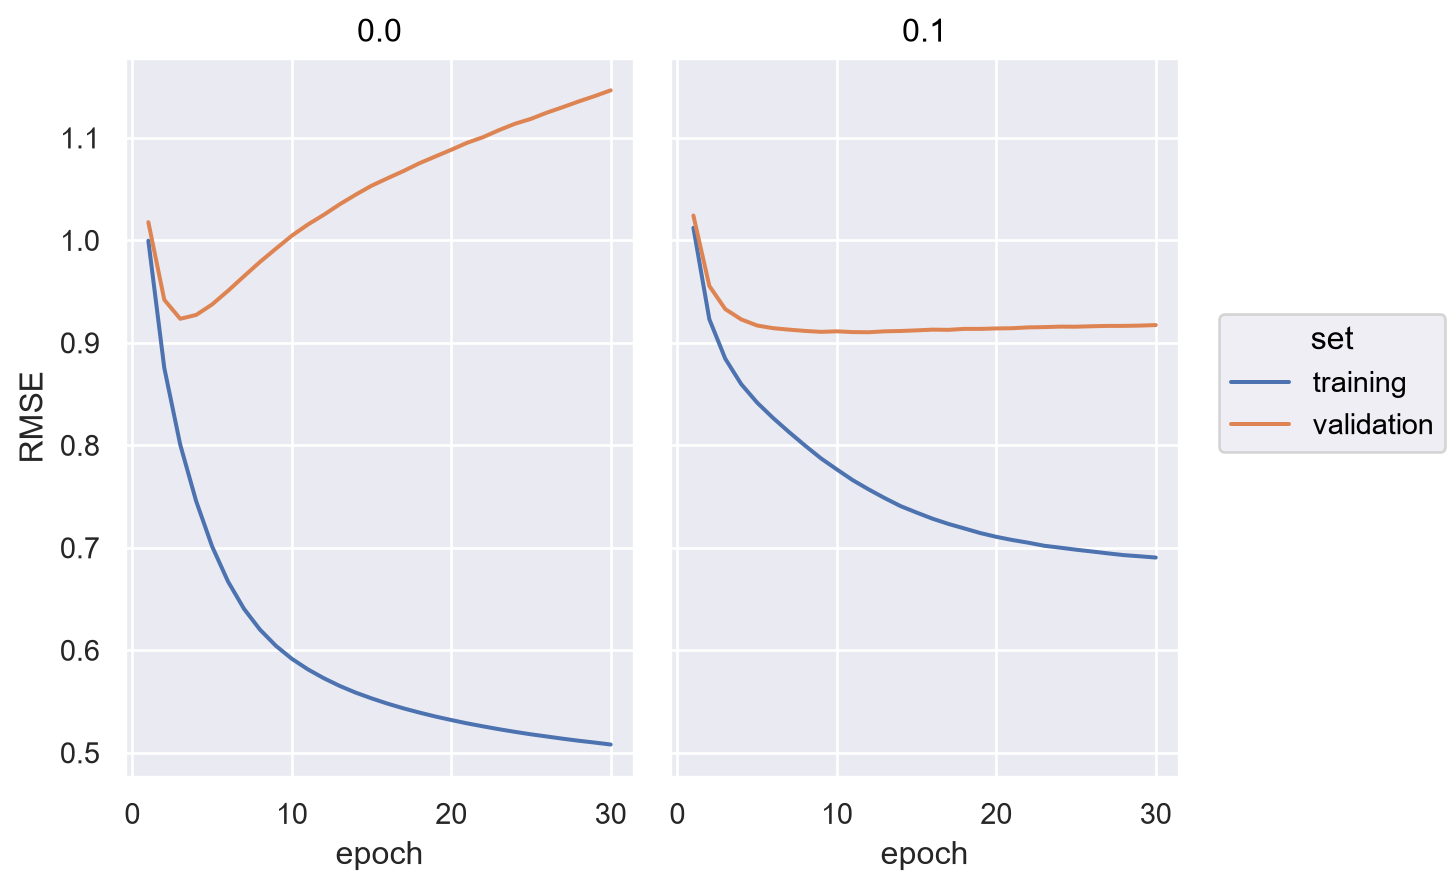

In [13]:
class MatrixFactorization(torch.nn.Module):
  def __init__(self, q):
    super().__init__()
    self.U, self.V = torch.nn.Embedding(n_users, q), torch.nn.Embedding(n_items, q)
    self.b_user, self.b_item = torch.nn.Embedding(n_users, 1), torch.nn.Embedding(n_items, 1)
    torch.nn.init.normal_(self.U.weight, 0, 0.01); torch.nn.init.normal_(self.V.weight, 0, 0.01)
    torch.nn.init.zeros_(self.b_user.weight); torch.nn.init.zeros_(self.b_item.weight)
    self.mu = torch.nn.Parameter(torch.tensor(float(mu)))
  def forward(self, u, i):
    return self.mu + self.b_user(u)[:, 0] + self.b_item(i)[:, 0] + (self.U(u) * self.V(i)).sum(dim=1)
  def penalty(self, u, i):
    return ((self.U(u) ** 2).sum(dim=1) + (self.V(i) ** 2).sum(dim=1) + self.b_user(u)[:, 0] ** 2 + self.b_item(i)[:, 0] ** 2).mean()

def train_mf(q=20, lam=0.1, epochs=30, lr=5e-3, batch=1024, seed=0):
  torch.manual_seed(seed)
  model = MatrixFactorization(q)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)
  u, i, r = torch.tensor(u_train), torch.tensor(i_train), torch.tensor(r_train, dtype=torch.float32)
  history = []
  for epoch in range(epochs):
    for b in torch.randperm(len(r)).split(batch):
      loss = ((model(u[b], i[b]) - r[b]) ** 2).mean() + lam * model.penalty(u[b], i[b])
      optimizer.zero_grad(); loss.backward(); optimizer.step()
    with torch.no_grad():
      history.append({'epoch': epoch + 1, 'lambda': lam, 'training': rmse(model(u, i).numpy(), r_train),
                      'validation': rmse(model(torch.tensor(u_valid), torch.tensor(i_valid)).numpy(), r_valid)})
  return model, history
histories = []
for lam in [0, 0.1]:
  mf, history = train_mf(lam=lam)
  histories += history
histories = pl.DataFrame(histories)
print(histories.group_by('lambda').agg(pl.col('validation').min().alias('best validation RMSE'),
                                       pl.col('epoch').get(pl.col('validation').arg_min()).alias('best epoch')))
(so.Plot(histories.unpivot(index=['epoch', 'lambda'], variable_name='set', value_name='RMSE'), x='epoch', y='RMSE', color='set')
 .facet(col='lambda').add(so.Line()))

**Conclusion** Without penalty, the factorization overfits after $3$ epochs: the training RMSE keeps decreasing (down to $0.51$) while the validation RMSE increases from $0.923$ to $1.15$. With $\lambda = 0.1$, the validation RMSE decreases until epoch $12$ ($0.910$, the best rating model so far) and stays almost flat afterwards: the penalty makes the training robust to the number of epochs, while early stopping alone would have to stop at epoch $3$. Writing the model in PyTorch costs a few lines and gives SGD, mini-batches and automatic differentiation, which makes it easy to change the model (next blocks).

---

## 5. From ratings to recommendations: ranking metrics

A recommender system shows a short list of items: only the top of the list matters (lecture: *Ranking Metrics*). For each user, we rank *all* the movies he or she has not rated in the training set (ranking against a few sampled movies may change the comparison of the methods, see *Offline Evaluation Pitfalls*), keep the top $K = 10$, and consider as relevant the movies of the test set rated $4$ or $5$. The precision $P@K$ and the recall $R@K$ are the fractions of relevant movies in the list and of the relevant movies in the list; $\text{NDCG}@K$ discounts the hits by $1/\log_2(1 + \text{rank})$ and normalizes by the best possible value; MRR@K averages the reciprocal rank of the first top-K hit, scoring a miss as zero. The averages include users with at least one relevant held-out movie. The *coverage* is the fraction of the catalog that appears in at least one list.

In [14]:
relevant = {}
for u, i, r in zip(u_test, i_test, r_test):
  if r >= 4:
    relevant.setdefault(u, set()).add(i)
def ranking_metrics(scores, K=10):
  """scores: n_users x n_items matrix, the higher the better; the movies of the training set are excluded."""
  discount = 1 / np.log2(np.arange(2, K + 2))
  scores = np.where(W, -np.inf, scores)
  top = np.argpartition(-scores, K - 1, axis=1)[:, :K]
  top = np.take_along_axis(top, np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1), axis=1)
  metrics = []
  for u, rel in relevant.items():
    hits = np.isin(top[u], list(rel))
    metrics.append({f'P@{K}': hits.mean(), f'R@{K}': hits.sum() / len(rel),
                    f'NDCG@{K}': (hits * discount).sum() / discount[:min(len(rel), K)].sum(),
                    f'MRR@{K}': 1 / (np.argmax(hits) + 1) if hits.any() else 0})
  return pl.DataFrame(metrics).mean().with_columns(coverage=pl.lit(len(np.unique(top[list(relevant)])) / n_items))

**Question** *Predict before you run:* which of the methods has the best NDCG@10? Compute the test RMSE and the ranking metrics of: the popularity (number of training ratings of each movie, the same for every user), the bias model, the ALS model ($q = 10$, $\lambda = 20$) and the PyTorch factorization (trained with $\lambda = 0.1$ for the best number of epochs). Display the top $5$ of the first user for each method.

**Answer**

In [15]:
popularity = np.tile(np.bincount(i_train, minlength=n_items).astype(float), (n_users, 1))
biases = mu + b_user[:, None] + b_item[None, :]
U_als, V_als = als(10, 20)
best_epoch = histories.filter(pl.col('lambda') == 0.1).sort('validation')['epoch'][0]
mf, _ = train_mf(lam=0.1, epochs=best_epoch)
with torch.no_grad():
  mf_scores = (mf.mu + mf.b_user.weight + mf.b_item.weight.T + mf.U.weight @ mf.V.weight.T).numpy()
scores = {'popularity': popularity, 'biases': biases, 'ALS': biases + U_als @ V_als.T, 'PyTorch MF': mf_scores}
comparison = pl.concat([ranking_metrics(s).with_columns(method=pl.lit(name),
                         test_RMSE=pl.lit(rmse(s[u_test, i_test], r_test) if name != 'popularity' else None, dtype=pl.Float64)) for name, s in scores.items()])
print(comparison.select('method', 'test_RMSE', 'P@10', 'R@10', 'NDCG@10', 'MRR@10', 'coverage'))
pl.DataFrame({name: titles[np.argsort(-np.where(W[0], -np.inf, s[0]))[:5]] for name, s in scores.items()})

shape: (4, 7)
┌────────────┬───────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ method     ┆ test_RMSE ┆ P@10     ┆ R@10     ┆ NDCG@10  ┆ MRR@10   ┆ coverage │
│ ---        ┆ ---       ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str        ┆ f64       ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞════════════╪═══════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ popularity ┆ null      ┆ 0.071564 ┆ 0.130521 ┆ 0.116865 ┆ 0.215452 ┆ 0.029727 │
│ biases     ┆ 0.938191  ┆ 0.039573 ┆ 0.053677 ┆ 0.051842 ┆ 0.107503 ┆ 0.022592 │
│ ALS        ┆ 0.917375  ┆ 0.051303 ┆ 0.065958 ┆ 0.066787 ┆ 0.134081 ┆ 0.057075 │
│ PyTorch MF ┆ 0.908968  ┆ 0.033175 ┆ 0.045553 ┆ 0.046328 ┆ 0.099142 ┆ 0.25327  │
└────────────┴───────────┴──────────┴──────────┴──────────┴──────────┴──────────┘


popularity,biases,ALS,PyTorch MF
str,str,str,str
"""Return of the Jedi (1983)""","""Schindler's List (1993)""","""Casablanca (1942)""","""Two or Three Things I Know Abo…"
"""Fargo (1996)""","""Casablanca (1942)""","""Fargo (1996)""","""Close Shave, A (1995)"""
"""Liar Liar (1997)""","""Wrong Trousers, The (1993)""","""Wrong Trousers, The (1993)""","""They Made Me a Criminal (1939)"""
"""English Patient, The (1996)""","""Close Shave, A (1995)""","""Close Shave, A (1995)""","""Wrong Trousers, The (1993)"""
"""Scream (1996)""","""Shawshank Redemption, The (199…","""Secrets & Lies (1996)""","""Delta of Venus (1994)"""


**Conclusion** The ranking metrics reverse the order given by the RMSE: the PyTorch factorization has the best test RMSE ($0.909$) but the worst NDCG@10 ($0.046$), and the popularity, which predicts no rating at all, has the best NDCG@10 ($0.117$) and MRR@10. The rating models recommend obscure movies that they predict to be very good (*They Made Me a Criminal*, *Delta of Venus*...) but that nobody watches, while the test set only contains movies that the users chose to watch. The bias and ALS models recommend acclaimed classics (*Casablanca*, *Schindler's List*), better but still not what the users watched next. The popularity has a tiny coverage ($3\%$ of the catalog): it shows the same blockbusters to everybody. RMSE is not ranking, and what is evaluated must match what is recommended.

---

The rating models predict well how much a user would like a movie *if he or she watched it*, but the test set only contains the movies the users chose to watch and rate. A top-$N$ recommender must also predict *which* movies a user will watch: this is the *implicit feedback* view, where the data are the pairs $(u, i)$ observed, whatever the rating.

**Question** Build an implicit item-based recommender: from the binary matrix `W` (rated or not), compute the cosine similarities between the items, and score each movie for a user by the sum of its similarities with the movies he or she rated. Compare its ranking metrics with the previous ones.

**Answer**

In [16]:
B = W.astype(float)
item_norms = np.sqrt(B.sum(axis=0)) + 1e-9
implicit_similarity = (B.T @ B) / np.outer(item_norms, item_norms)
np.fill_diagonal(implicit_similarity, 0)
scores['implicit item kNN'] = B @ implicit_similarity
pl.concat([comparison.drop('test_RMSE'), ranking_metrics(scores['implicit item kNN']).with_columns(method=pl.lit('implicit item kNN'))],
          how='diagonal').select('method', 'P@10', 'R@10', 'NDCG@10', 'MRR@10', 'coverage')

method,P@10,R@10,NDCG@10,MRR@10,coverage
str,f64,f64,f64,f64,f64
"""popularity""",0.071564,0.130521,0.116865,0.215452,0.029727
"""biases""",0.039573,0.053677,0.051842,0.107503,0.022592
"""ALS""",0.051303,0.065958,0.066787,0.134081,0.057075
"""PyTorch MF""",0.033175,0.045553,0.046328,0.099142,0.25327
"""implicit item kNN""",0.11481,0.230258,0.203785,0.328223,0.112366


**Conclusion** The implicit item-based recommender, which only uses *which* movies were rated, has the best ranking metrics: NDCG@10 of $0.20$ (almost twice the popularity), recall@10 of $0.23$ and MRR@10 of $0.33$, with a coverage of $11\%$. It models the probability of watching a movie given the movies already watched, which is what a top-$N$ recommendation needs; the ratings themselves are less useful for this task than the fact that a movie was rated.

---

## About this lab

**Use of AI.** Artificial intelligence tools have been used to revise the content of this lab. The main contributor takes full responsibility for this content.

**License.** The texts of this lab are under the [Creative Commons Attribution-ShareAlike 4.0](https://creativecommons.org/licenses/by-sa/4.0/) license (CC BY-SA 4.0), and its code under the [MIT](https://opensource.org/license/mit) license; the datasets keep their own licenses. Main contributor: E. Le Pennec. Contributors: S. Boucheron, A. Dieuleveut, A.K. Fermin, S. Gadat, S. Gaiffas, B. Goujaud, A. Guilloux, Ch. Keribin, Th. Klein, E. Matzner, J. Read, M. Sangnier, E. Scornet.